<a href="https://colab.research.google.com/github/raichuuu01/APS_Lab/blob/main/25-08-2026-Breast_Cancer_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
data=load_breast_cancer()

X=pd.DataFrame(data.data,columns=data.feature_names)
y=pd.Series((data.target==0).astype(int), name="malignant")

print(y.value_counts())

print("Feature matrix shape: ", X.shape)
print("Target shape: ", y.shape)
print("Class names: ", data.target_names)





malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape:  (569, 30)
Target shape:  (569,)
Class names:  ['malignant' 'benign']


In [4]:
class_counts=y.value_counts().sort_index()
class_distribution=pd.DataFrame(
    {
        "Class": data.target_names,
        "Count": class_counts.values,
        "Probability": class_counts.values/len(y)
    }
)
print(class_distribution)

       Class  Count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


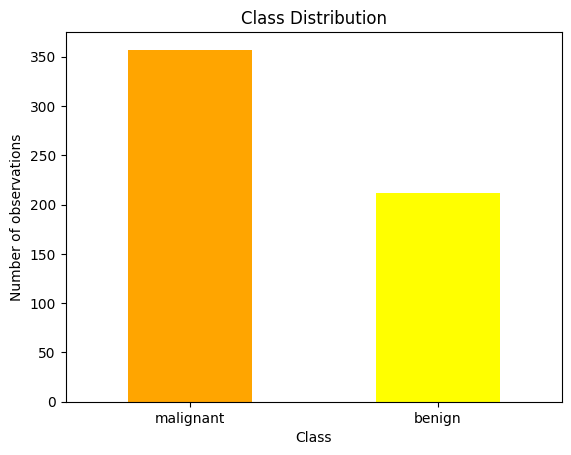

In [10]:
class_distribution.plot(x="Class", y="Count", kind="bar",legend=False, color=["orange","yellow"])

plt.ylabel("Number of observations")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

In [12]:
from pandas.core.api import value_counts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Training size: ", len(y_train))
print("Testing size: ", len(y_test))

print("\nTraining Proportions: ")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting Proportions: ")
print(y_test.value_counts(normalize=True).sort_index)



Training size:  455
Testing size:  114

Training Proportions: 
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Testing Proportions: 
<bound method Series.sort_index of malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64>


In [14]:
from sklearn.pipeline import make_pipeline
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
model.fit(X_train,y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [16]:
probabilities=model.predict_proba(X_test)
print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]
